# Trajectory quality control

## tl;dr

**Template: the default input is a synthetic teaching fixture.** Its output
is not a result about medaka. Use this notebook to learn an auditable analysis
workflow, then pin a supervisor-approved research export before adapting it.

The calculation separates finite reconstruction, observed valid position,
and declared identity-supported observed position. It keeps missing rows in
the denominator and breaks plots at missingness and segment boundaries.

Read `README.md`, `config.toml`, and the root `AGENTS.md`. Restart the kernel
and run all cells in order; inspect the saved output before handoff.

## Context & Methods

**Question:** How much of a declared recording window has observed positions
attached to supported trial-wide identities?

### Key assumptions

- One recording, one body-reference point per local segment/frame, with
  known regular sampling. This is not a loader for raw SLEAP candidates.
- The configured window starts at or after 300 s of recording time.
- Every expected fish-sample remains in the denominator, including absent
  predictions. Row counts do not establish biological replication.
- Research support flags require upstream evidence; this notebook cannot
  validate the identity of a fish. Anonymous IDs do not imply F/M1/M2 names.
- Interpolated positions do not count as observed reconstruction.
- Irregular sampling needs a different, documented duration calculation.

### 1. Check the environment and configuration

The kernel must use this project's virtualenv. The working directory must
be this analysis folder, containing `config.toml` and `analysis.ipynb`.
There are no package-install cells or machine-specific drive letters.

In [1]:
import hashlib
import importlib.metadata
import json
import re
import sys
import tomllib
from datetime import UTC, datetime
from pathlib import Path

import matplotlib.pyplot as plt
import nbformat
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from medaka3d import load_paths
from medaka3d.provenance import provenance

analysis_dir = Path.cwd().resolve()
config_path = analysis_dir / "config.toml"
if not config_path.is_file():
    raise FileNotFoundError("Run the notebook from its analysis folder containing config.toml.")
config = tomllib.loads(config_path.read_text(encoding="utf-8"))
input_config = config["input"]
window = config["window"]
input_kind = input_config["kind"]
if input_kind not in {"synthetic", "research"}:
    raise ValueError("Set input.kind explicitly to synthetic or research.")
if not re.fullmatch(r"[a-z0-9_]+", config["analysis"]["slug"]):
    raise ValueError("Use a lowercase analysis slug with letters, digits, and underscores.")

plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_colwidth", None)
print(f"Kernel: {sys.executable}")
print(f"Input kind: {input_kind}; recording: {input_config['recording_id']}")
print(f"Input run: {input_config['run_id']}")
if input_kind == "synthetic":
    display(Markdown("**SYNTHETIC TUTORIAL ONLY — no research result.**"))
display(pd.Series(config["analysis"], name="Analysis settings").to_frame())

Kernel: C:\Users\machi\Documents\GitHub\medaka-3d\.venv\Scripts\python.exe
Input kind: synthetic; recording: SYNTHETIC
Input run: synthetic_tutorial_v1


**SYNTHETIC TUTORIAL ONLY — no research result.**

,Analysis settings
slug,trajectory_qc
owner,UNASSIGNED
question,How much of the window has observed positions with supported trial IDs?


## Data

### 2. Resolve a fixed input and verify its checksum

Research inputs live under `work_dir` or `asset_root`, configured in the
repository's ignored `configs/paths.local.toml`. Pin their extraction commit,
run, schema, body reference, and identity-evidence references. A checksum
match proves which file was loaded; it does not prove scientific validity.

In [2]:
paths = None
root_name = input_config["root"]
if input_kind == "synthetic":
    if root_name != "analysis_dir":
        raise ValueError("The teaching fixture must be relative to the analysis directory.")
    input_root = analysis_dir
else:
    if root_name not in {"work_dir", "asset_root"}:
        raise ValueError("Research data must use a configured work_dir or asset_root.")
    if config["analysis"]["owner"].strip() in {"", "UNASSIGNED"}:
        raise ValueError("Assign the research analysis owner in config.toml.")
    if not re.fullmatch(r"[0-9a-fA-F]{40}", input_config["extraction_commit"]):
        raise ValueError("Research input requires the full 40-character extraction commit.")
    for field in (
        "recording_id",
        "run_id",
        "provenance_ref",
        "schema_ref",
        "identity_evidence_ref",
        "body_reference",
    ):
        value = input_config[field].strip()
        if not value or "synthetic" in value.lower() or value.upper() == "UNASSIGNED":
            raise ValueError(f"Replace the teaching placeholder for input.{field}.")
    paths = load_paths()
    input_root = getattr(paths, root_name).resolve()

relative_csv = Path(input_config["csv"])
if relative_csv.is_absolute():
    raise ValueError("input.csv must be relative to its declared root.")
input_path = (input_root / relative_csv).resolve()
if not input_path.is_relative_to(input_root):
    raise ValueError("input.csv must stay within its declared root.")
expected_sha256 = input_config["sha256"].lower()
if not re.fullmatch(r"[0-9a-f]{64}", expected_sha256):
    raise ValueError("Set the input file's full SHA-256 in config.toml.")
actual_sha256 = hashlib.sha256(input_path.read_bytes()).hexdigest()
if actual_sha256 != expected_sha256:
    raise ValueError("Input checksum mismatch. Investigate the version; do not bypass this check.")
print(f"Verified input: {input_path.name}; SHA-256: {actual_sha256}")

Verified input: synthetic_tracks.csv; SHA-256: 2101eaf42e8b9faf4aaad13220e3d3d02a67cac12de5042e79e04a377f645171


### 3. Validate the example table contract

Explicitly adapt a real export to the documented body-reference contract.
Do not infer support flags from coordinates or numeric tracker slots. Keep
the original source and adapter provenance. Empty trial IDs stay unresolved.

In [3]:
tracks = pd.read_csv(input_path, dtype={"segment_id": "string", "trial_fish_id": "string"})
required = {
    "frame",
    "recording_time_s",
    "segment_id",
    "trial_fish_id",
    "x_mm",
    "y_mm",
    "z_mm",
    "position_valid",
    "identity_valid",
    "is_observed",
}
missing_columns = required - set(tracks.columns)
if missing_columns:
    raise ValueError(f"Missing columns: {sorted(missing_columns)}. Review the export/adapter.")
for flag in ("position_valid", "identity_valid", "is_observed"):
    if not tracks[flag].isin([0, 1]).all():
        raise ValueError(f"{flag} must contain explicit 0/1 values without missing entries.")
    tracks[flag] = tracks[flag].astype(bool)
for column in ("frame", "recording_time_s", "x_mm", "y_mm", "z_mm"):
    tracks[column] = pd.to_numeric(tracks[column], errors="raise")
if not np.isfinite(tracks[["frame", "recording_time_s"]]).all().all():
    raise ValueError("Frame and recording time must be finite.")
if (tracks["frame"] < 0).any() or (tracks["frame"] % 1 != 0).any():
    raise ValueError("Recording frames must be non-negative integers.")
if tracks["segment_id"].isna().any() or tracks["segment_id"].str.strip().eq("").any():
    raise ValueError("Every source row needs a local segment ID.")
tracks["trial_fish_id"] = tracks["trial_fish_id"].str.strip().replace("", pd.NA)
if not tracks["identity_valid"].eq(tracks["trial_fish_id"].notna()).all():
    raise ValueError("Unsupported trial IDs must be null; supported IDs must be present.")
if (tracks.groupby("segment_id")["trial_fish_id"].nunique() > 1).any():
    raise ValueError("A continuous local segment maps to multiple trial-wide IDs.")
if tracks.duplicated(["frame", "segment_id"]).any():
    raise ValueError("Duplicate segment/frame rows: check joins and body-node selection.")
if (tracks.groupby("frame")["recording_time_s"].nunique() > 1).any():
    raise ValueError("One recording frame maps to multiple timestamps.")
if (tracks.groupby("recording_time_s")["frame"].nunique() > 1).any():
    raise ValueError("One timestamp maps to multiple recording frames.")
finite_position = np.isfinite(tracks[["x_mm", "y_mm", "z_mm"]]).all(axis=1)
if (tracks["position_valid"] & ~finite_position).any():
    raise ValueError("A position-valid row has missing/non-finite coordinates.")
tracks["finite_position"] = finite_position
tracks = tracks.sort_values(["recording_time_s", "segment_id"]).reset_index(drop=True)
display(tracks.head(6))

,frame,recording_time_s,segment_id,trial_fish_id,x_mm,y_mm,z_mm,position_valid,identity_valid,is_observed,finite_position
0,299,299,a1,A,9.0,20.0,30.0,True,True,True,True
1,299,299,b1,B,29.0,40.0,50.0,True,True,True,True
2,299,299,c1,C,49.0,60.0,70.0,True,True,True,True
3,300,300,a1,A,10.0,20.0,30.0,True,True,True,True
4,300,300,b1,B,30.0,40.0,50.0,True,True,True,True
5,300,300,c1,C,50.0,60.0,70.0,True,True,True,True


### 4. Declare the denominator before filtering

The window is half-open: `[start_s, end_s)`. All expected fish-samples count,
even when a frame or fish has no row. These are sample counts on a verified
regular grid, not independent animals or an irregular-time duration estimate.

In [4]:
start_s = float(window["start_s"])
end_s = float(window["end_s"])
interval_s = float(window["sample_interval_s"])
expected_individuals = window["expected_individuals"]
if not np.isfinite([start_s, end_s, interval_s]).all():
    raise ValueError("Window and sampling parameters must be finite.")
if start_s < 300 or end_s <= start_s or interval_s <= 0 or expected_individuals != 3:
    raise ValueError("Use a positive post-preparation window, positive cadence, and three fish.")
sample_count = (end_s - start_s) / interval_s
if not np.isclose(sample_count, round(sample_count), rtol=0, atol=1e-6):
    raise ValueError("This example requires a whole number of regular sampling intervals.")
expected_times = round(sample_count)
if expected_times < 1:
    raise ValueError("The declared window must contain at least one expected sample.")
expected_fish_samples = expected_times * expected_individuals
selected = tracks.loc[
    tracks["recording_time_s"].ge(start_s) & tracks["recording_time_s"].lt(end_s)
].copy()
grid_coordinates = (selected["recording_time_s"] - start_s) / interval_s
if not np.isclose(grid_coordinates, np.rint(grid_coordinates), rtol=0, atol=1e-6).all():
    raise ValueError("Input times do not match the declared regular grid. Review timing.")
selected["sample_index"] = np.rint(grid_coordinates).astype(int)
if (selected.groupby("sample_index").size() > expected_individuals).any():
    raise ValueError("Too many reconstructed rows per sample for this body-reference contract.")
supported_rows = selected.loc[selected["identity_valid"]]
if supported_rows.duplicated(["sample_index", "trial_fish_id"]).any():
    raise ValueError("A trial-wide ID is assigned twice at one sample.")
if supported_rows["trial_fish_id"].nunique() > expected_individuals:
    raise ValueError("More supported trial IDs than individuals: review ID scope.")
print(f"Window: [{start_s:g}, {end_s:g}) s; expected fish-samples: {expected_fish_samples}")
print(f"Sampling basis: {window['sampling_basis']}")

Window: [300, 306) s; expected fish-samples: 18
Sampling basis: Synthetic regular 1 Hz samples, not an acquisition frame rate.


## Results

### 5. Keep reconstruction, observation, and identity claims separate

The primary example measure uses observed, valid positions with supplied
identity support. It excludes interpolation and unresolved correspondence.
An empty or failed input does not shorten the expected denominator.

In [5]:
selected["observed_valid"] = (
    selected["finite_position"] & selected["position_valid"] & selected["is_observed"]
)
selected["accepted"] = selected["observed_valid"] & selected["identity_valid"]
counts = [
    int(selected["finite_position"].sum()),
    int(selected["observed_valid"].sum()),
    int(selected["accepted"].sum()),
]
summary = pd.DataFrame(
    {
        "measure": [
            "Finite reconstruction",
            "Observed + position valid",
            "Declared supported + observed",
        ],
        "fish_samples": counts,
        "expected_fish_samples": expected_fish_samples,
    }
)
summary["coverage_percent"] = 100 * summary["fish_samples"] / expected_fish_samples
display(summary.round({"coverage_percent": 1}))
coverage_percent = summary.iloc[2]["coverage_percent"]
display(
    Markdown(
        f"**{'Synthetic tutorial' if input_kind == 'synthetic' else 'Research input'}:** "
        f"{counts[2]}/{expected_fish_samples} expected fish-samples meet the declared "
        f"observed-position and identity-support flags ({coverage_percent:.1f}%). "
        "The flags themselves still require the documented evidence."
    )
)

,measure,fish_samples,expected_fish_samples,coverage_percent
0,Finite reconstruction,16,18,88.9
1,Observed + position valid,15,18,83.3
2,Declared supported + observed,13,18,72.2


**Synthetic tutorial:** 13/18 expected fish-samples meet the declared observed-position and identity-support flags (72.2%). The flags themselves still require the documented evidence.

### 6. Inspect coverage and gaps

The coverage axis starts at zero. The time plot shows one coordinate for a
compact QC example; adapt it to other axes and synchronized video review.
Plot each segment separately and reindex on the complete sampling grid so
missing or unsupported samples break the line. A smooth line is not proof
of a correct identity, and these panels do not validate a whole recording.

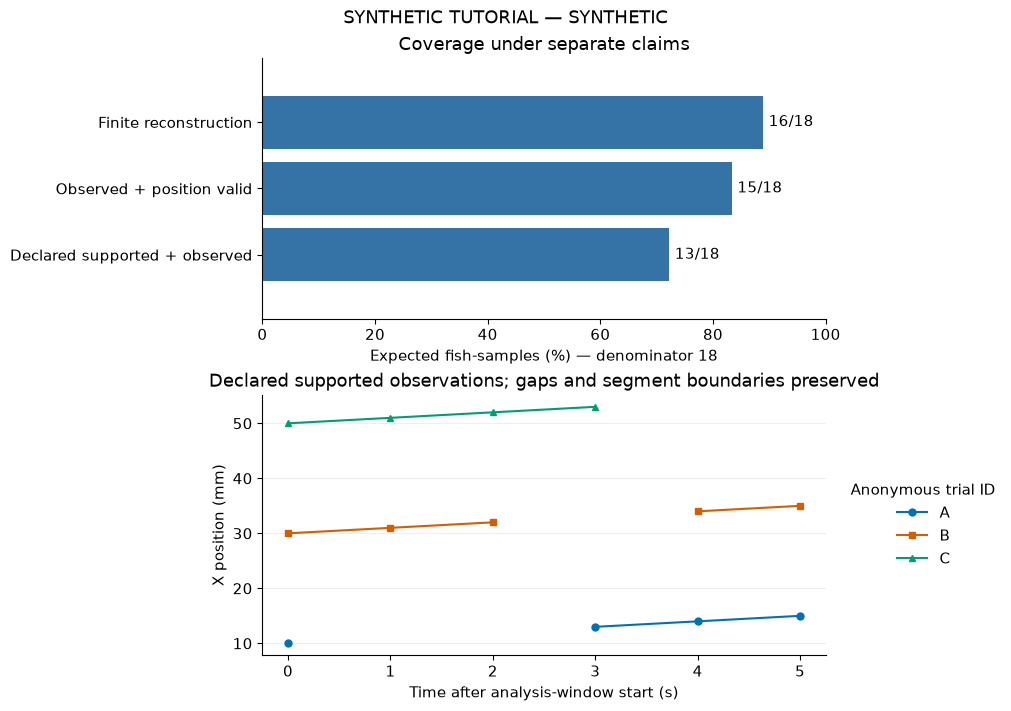

In [6]:
figure, axes = plt.subplots(2, 1, figsize=(10, 7), layout="constrained")
coverage_axis, position_axis = axes
coverage_axis.barh(summary["measure"], summary["coverage_percent"], color="#3572a5")
coverage_axis.invert_yaxis()
coverage_axis.set_xlim(0, 100)
coverage_axis.set_xlabel(f"Expected fish-samples (%) — denominator {expected_fish_samples}")
coverage_axis.set_title("Coverage under separate claims")
for index, row in summary.iterrows():
    percent = row["coverage_percent"]
    label_x = percent - 1 if percent > 90 else percent + 1
    coverage_axis.text(
        label_x,
        index,
        f"{row['fish_samples']}/{expected_fish_samples}",
        va="center",
        ha="right" if percent > 90 else "left",
    )
coverage_axis.margins(y=0.2)
accepted = selected.loc[selected["accepted"]]
palette = ["#0072b2", "#d55e00", "#009e73"]
markers = ["o", "s", "^"]
for index, (fish_id, fish) in enumerate(accepted.groupby("trial_fish_id", sort=True)):
    for segment_index, (_, segment) in enumerate(fish.groupby("segment_id", sort=True)):
        values = segment.set_index("sample_index")["x_mm"].reindex(range(expected_times))
        position_axis.plot(
            np.arange(expected_times) * interval_s,
            values,
            color=palette[index],
            marker=markers[index],
            markersize=5,
            label=str(fish_id) if segment_index == 0 else None,
        )
position_axis.set(
    xlabel="Time after analysis-window start (s)",
    ylabel="X position (mm)",
    title="Declared supported observations; gaps and segment boundaries preserved",
)
if not accepted.empty:
    position_axis.legend(
        title="Anonymous trial ID", loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False
    )
else:
    position_axis.text(
        0.5,
        0.5,
        "No accepted identity-bearing observations",
        ha="center",
        va="center",
        transform=position_axis.transAxes,
    )
position_axis.grid(axis="y", alpha=0.2)
figure.suptitle(
    f"{'SYNTHETIC TUTORIAL' if input_kind == 'synthetic' else 'Trajectory QC'} "
    f"— {input_config['recording_id']}"
)
display(
    figure,
    metadata={
        "image/png": {
            "alt": "Coverage bars for finite, observed-valid, and identity-supported observations; "
            "X position over time for anonymous IDs, with gaps and segment boundaries preserved."
        }
    },
)
plt.close(figure)

### 7. Check the result before interpretation

The known fixture has 18 expected fish-samples, 16 finite positions, 15
observed valid positions, and 13 declared supported observations. This
hand-count is an instructional calculation check, not a tracking benchmark.
Add independent checks appropriate to the real scientific question.

In [7]:
assert 0 <= counts[2] <= counts[1] <= counts[0] <= expected_fish_samples
if input_kind == "synthetic":
    assert expected_fish_samples == 18 and counts == [16, 15, 13]
    print("Synthetic fixture hand-count agrees: 13/18 primary fish-samples.")
print("Inspect plot breaks, units, input provenance, masks, and selection bias with the reviewer.")

Synthetic fixture hand-count agrees: 13/18 primary fish-samples.
Inspect plot breaks, units, input provenance, masks, and selection bias with the reviewer.


### 8. Export a versioned result with provenance

Each execution gets a new output run directory. Keep large artifacts outside
Git. The provenance below covers exporting these results and records the
configuration, input checksum, software versions, and notebook-source hash.
It does not turn earlier cell errors into a successful run.

In [8]:
timestamp = datetime.now(UTC).strftime("%Y%m%dT%H%M%S%fZ")
analysis_run_id = f"{config['analysis']['slug']}_{timestamp}"
output_root = (
    analysis_dir / "_outputs" if input_kind == "synthetic" else paths.work_dir / "analyses"
)
output_dir = output_root / config["analysis"]["slug"] / analysis_run_id
if output_dir.exists():
    raise FileExistsError("Output run already exists; preserve it and choose a new run ID.")
notebook_path = analysis_dir / "analysis.ipynb"
source_notebook = nbformat.read(notebook_path, as_version=4)
source_text = json.dumps([(cell.cell_type, cell.source) for cell in source_notebook.cells])
notebook_source_sha256 = hashlib.sha256(source_text.encode("utf-8")).hexdigest()
summary_path = output_dir / "coverage.csv"
figure_path = output_dir / "trajectory_qc.png"
snapshot_path = output_dir / "config.toml"
with provenance("student_trajectory_qc", output_dir) as record:
    record.input("tracks", input_path, sha256=actual_sha256)
    record.input(
        "configuration", config_path, sha256=hashlib.sha256(config_path.read_bytes()).hexdigest()
    )
    record.param("configuration", config)
    record.param("analysis_run_id", analysis_run_id)
    record.param("notebook_source_sha256", notebook_source_sha256)
    record.param(
        "software_versions",
        {
            name: importlib.metadata.version(name)
            for name in ("numpy", "pandas", "matplotlib", "nbformat")
        },
    )
    summary.to_csv(summary_path, index=False)
    figure.savefig(figure_path, dpi=150, bbox_inches="tight")
    snapshot_path.write_bytes(config_path.read_bytes())
    for name, artifact in (
        ("coverage", summary_path),
        ("figure", figure_path),
        ("configuration_snapshot", snapshot_path),
    ):
        record.output(name, artifact, sha256=hashlib.sha256(artifact.read_bytes()).hexdigest())
print(f"Output run: {analysis_run_id}")
print(f"Exports: {output_dir}")

Output run: trajectory_qc_20261026T040827528675Z
Exports: C:\Users\machi\Documents\GitHub\medaka-3d\analyses\_template\_outputs\trajectory_qc\trajectory_qc_20261026T040827528675Z


## Takeaways

Before submitting research work, replace the tutorial interpretation with:

- The observed finding, its denominator, and the exact input/output run IDs.
- What position and identity evidence was reviewed, and what remains unknown.
- Whether gaps concentrate around encounters/courtship, and how exclusions
  affect the interpretation. Do not treat retained time as all behavior.
- Limitations: this regular-grid QC is not an identity-accuracy estimator,
  biological hypothesis test, or certification of the extraction pipeline.
- The next decision and any unsuccessful approaches, also recorded in README.

**The default run is synthetic only.** For research, agree the experimental
unit with the supervisor using `medaka3d.cohort`; repeated frames and days
of the same fish are not independent biological replicates.